# 3D Helmholtz PFDM — numerics-informed hyperparameter experiment

We consider

\[
(-\Delta+\kappa^2)u=f
\qquad \text{on }(0,1)^3,
\]

with homogeneous Dirichlet boundary conditions and manufactured exact solution

\[
u^\star(x,y,z)=\sin(\pi x)\sin(\pi y)\sin(\pi z).
\]

The proposed hyperparameter rule is

\[
\tau=p=2,\qquad
C=\widehat C_{\rm defect},\qquad
\sigma_f=\|u_h\|_\infty,
\]

while the Matérn-\(3/2\) length scale is chosen from the adjacent-grid prior correlation

\[
\rho(h)\in\{0.3,0.5,0.7,0.8\}.
\]

We repeat the experiment for

\[
N_x\in\{4,5,6,8\},
\qquad h=\frac{1}{N_x+1}.
\]

For each \((h,\rho)\), we report \(\widehat C\), oracle \(C\) (diagnostic only), posterior mean error, 95% coverage, and average CI half-width.


In [1]:
using LinearAlgebra
using SparseArrays
using Statistics
using SpecialFunctions
using Printf
using Plots

println("Packages loaded.")


Packages loaded.


In [2]:
# ============================================================
# Problem and Matérn-3/2 kernel
# ============================================================

ν_fixed = 1.5
p_order = 2
τ_fixed = 2
k_wave  = 1.0
jitter  = 1e-10

u_exact(x, y, z, k) =
    sin(π*x) * sin(π*y) * sin(π*z)

f_func(x, y, z, k) =
    (3π^2 + k^2) * sin(π*x) * sin(π*y) * sin(π*z)

function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ

    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_3d(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = length(X1), length(X2)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_3d(
            X1[i], X2[j];
            ν=ν, ℓ=ℓ, σf=σf
        )
    end
    return K
end


kernel_matrix_3d (generic function with 1 method)

In [3]:
# ============================================================
# 3D Helmholtz finite-difference operator
# D_h = -Delta_h + k^2 I
# ============================================================

function build_Dh_3d_helmholtz(Nx, Ny, Nz, h, k)
    N = Nx * Ny * Nz
    index(i,j,l) = i + (j-1)*Nx + (l-1)*Nx*Ny

    rows = Int[]
    cols = Int[]
    vals = Float64[]

    for l in 1:Nz, j in 1:Ny, i in 1:Nx
        q = index(i,j,l)

        push!(rows,q)
        push!(cols,q)
        push!(vals, 6.0/h^2 + k^2)

        if i > 1
            push!(rows,q); push!(cols,index(i-1,j,l)); push!(vals,-1.0/h^2)
        end
        if i < Nx
            push!(rows,q); push!(cols,index(i+1,j,l)); push!(vals,-1.0/h^2)
        end
        if j > 1
            push!(rows,q); push!(cols,index(i,j-1,l)); push!(vals,-1.0/h^2)
        end
        if j < Ny
            push!(rows,q); push!(cols,index(i,j+1,l)); push!(vals,-1.0/h^2)
        end
        if l > 1
            push!(rows,q); push!(cols,index(i,j,l-1)); push!(vals,-1.0/h^2)
        end
        if l < Nz
            push!(rows,q); push!(cols,index(i,j,l+1)); push!(vals,-1.0/h^2)
        end
    end

    return sparse(rows, cols, vals, N, N)
end

function make_grid_3d(Nx)
    h = 1.0 / (Nx + 1)
    xs = collect(range(h, step=h, length=Nx))
    ys = collect(range(h, step=h, length=Nx))
    zs = collect(range(h, step=h, length=Nx))

    X = [[x,y,z] for z in zs for y in ys for x in xs]

    return h, xs, ys, zs, X
end

function solve_fdm_helmholtz(Nx; k=k_wave)
    h, xs, ys, zs, X = make_grid_3d(Nx)

    Dh = build_Dh_3d_helmholtz(
        Nx, Nx, Nx, h, k
    )

    b = [
        f_func(x,y,z,k)
        for z in zs, y in ys, x in xs
    ] |> vec

    u_fdm = Dh \ b

    return h, xs, ys, zs, X, Dh, b, u_fdm
end


solve_fdm_helmholtz (generic function with 1 method)

In [4]:
# ============================================================
# Coarsening-based C calibration in 3D
#
# D_h u - f = c(x) h^p + higher-order terms
#
# For u_h, evaluate the 2h Helmholtz stencil:
#
#   defect = D_{2h} u_h - f
#
# then
#
#   c_hat = defect / ((2^p - 1) h^p)
#   C_hat = mean(c_hat.^2)
#
# The reaction term k^2 u is evaluated pointwise and therefore
# contributes no additional discretisation error.
# ============================================================

function estimate_C_coarsening_3d(u_h, h, Nx; p=2, k=k_wave)

    U = reshape(u_h, Nx, Nx, Nx)
    h2 = 2.0*h

    centers = 2:(Nx-1)
    isempty(centers) &&
        error("Nx must be at least 3.")

    function uval(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        elseif 1 <= i <= Nx &&
               1 <= j <= Nx &&
               1 <= l <= Nx
            return U[i,j,l]
        else
            error("2h stencil left physical domain")
        end
    end

    defect = Float64[]
    c_hat  = Float64[]

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        D2h_u = (
            6uval(i,j,l)
            - uval(i-2,j,l) - uval(i+2,j,l)
            - uval(i,j-2,l) - uval(i,j+2,l)
            - uval(i,j,l-2) - uval(i,j,l+2)
        ) / h2^2 + k^2*uval(i,j,l)

        d = D2h_u - f_func(x,y,z,k)
        c = d / ((2.0^p - 1.0) * h^p)

        push!(defect, d)
        push!(c_hat, c)
    end

    C_hat = mean(c_hat.^2)

    return C_hat, c_hat, defect
end

# Oracle C on the SAME centers as the coarsening estimator.
# Diagnostic only; never used by the method.
function oracle_C_3d(h, Nx; p=2, k=k_wave)

    centers = 2:(Nx-1)
    vals = Float64[]

    function ustar(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        end
        return u_exact(i*h, j*h, l*h, k)
    end

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        Dh_u = (
            6ustar(i,j,l)
            - ustar(i-1,j,l) - ustar(i+1,j,l)
            - ustar(i,j-1,l) - ustar(i,j+1,l)
            - ustar(i,j,l-1) - ustar(i,j,l+1)
        ) / h^2 + k^2*ustar(i,j,l)

        e = Dh_u - f_func(x,y,z,k)
        push!(vals, e / h^p)
    end

    return mean(vals.^2)
end


oracle_C_3d (generic function with 1 method)

In [5]:
# ============================================================
# Matérn-3/2: adjacent-grid correlation rho(h) -> ell
#
# rho(h) = (1+z)exp(-z), z=sqrt(3)h/ell
# ============================================================

function ell_from_rho_matern32(h, rho; tol=1e-12, maxiter=200)
    @assert 0.0 < rho < 1.0

    fz(z) = (1.0 + z) * exp(-z) - rho

    lo = 0.0
    hi = 1.0

    while fz(hi) > 0.0
        hi *= 2.0
    end

    for _ in 1:maxiter
        mid = 0.5*(lo + hi)

        if fz(mid) > 0.0
            lo = mid
        else
            hi = mid
        end

        if hi - lo < tol
            break
        end
    end

    z = 0.5*(lo + hi)
    return sqrt(3.0)*h/z
end

for rho in [0.3,0.5,0.7,0.8]
    @printf(
        "rho=%.1f -> ell/h=%.4f\n",
        rho,
        ell_from_rho_matern32(1.0,rho)
    )
end


rho=0.3 -> ell/h=0.7101
rho=0.5 -> ell/h=1.0320
rho=0.7 -> ell/h=1.5784
rho=0.8 -> ell/h=2.1010


In [6]:
# ============================================================
# PFDM posterior on a fine test grid
# ============================================================

function run_pfdm_helmholtz(
    Nx; rho_adj, C, σf, Nx_test=31,
    ν=ν_fixed, τ=τ_fixed, k=k_wave
)
    h, xs, ys, zs, X, Dh, b, u_fdm = solve_fdm_helmholtz(Nx; k=k)
    ell = ell_from_rho_matern32(h, rho_adj)

    K = kernel_matrix_3d(X, X; ν=ν, ℓ=ell, σf=σf)
    noise_var = C*h^(2τ)
    A = Hermitian(Dh*K*Dh' + noise_var*I + jitter*I)
    chol = cholesky(A)
    alpha = chol \ b

    # fine test grid
    ht = 1.0/(Nx_test+1)
    xt = collect(range(ht, step=ht, length=Nx_test))
    Xtest = [[x,y,z] for z in xt for y in xt for x in xt]

    Kstar = kernel_matrix_3d(Xtest, X; ν=ν, ℓ=ell, σf=σf)
    mu = Kstar * (Dh' * alpha)

    B = Dh * Kstar'
    V = chol.L \ B
    var_post = σf^2 .- vec(sum(V.^2, dims=1))
    std_post = sqrt.(max.(var_post,0.0))

    u_true = [u_exact(x,y,z,k) for z in xt for y in xt for x in xt]

    return (h=h, xt=xt, Xtest=Xtest, u_fdm=u_fdm, u_true=u_true,
            mu=mu, std=std_post, ell=ell)
end

function posterior_metrics(mu,std,u_true)
    err = mu .- u_true
    rmse = sqrt(mean(err.^2))
    linf = maximum(abs.(err))
    coverage = mean(abs.(err) .<= 1.96 .* std)
    mean_halfwidth = mean(1.96 .* std)
    return rmse,linf,coverage,mean_halfwidth
end


posterior_metrics (generic function with 1 method)

In [7]:
# ============================================================
# Proposed hyperparameter sweep
# ============================================================

Nx_list  = [4, 5, 6, 8]
rho_grid = [0.3, 0.5, 0.7, 0.8]
Nx_test = 31

results = NamedTuple[]

println("=== 3D Helmholtz: proposed hyperparameter experiment ===")
println("tau = p = 2")
println("sigma_f = ||u_h||_inf")
println("C = coarsening-defect estimator")
println("ell determined by adjacent-grid rho(h)")
println("metrics evaluated on fine test grid: Nx_test = $(Nx_test)")
println()

for nx in Nx_list

    h, xs, ys, zs, X, Dh, b, u_fdm =
        solve_fdm_helmholtz(nx)

    sigma_rms = sqrt(mean(u_fdm.^2))
    sigma_max = maximum(abs.(u_fdm))
    sigma_used = sigma_max

    C_hat, c_hat, defect =
        estimate_C_coarsening_3d(
            u_fdm, h, nx;
            p=p_order
        )

    C_oracle =
        oracle_C_3d(
            h, nx;
            p=p_order
        )

    u_true = [
        u_exact(x,y,z,k_wave)
        for z in zs, y in ys, x in xs
    ] |> vec

    fdm_linf =
        maximum(abs.(u_fdm - u_true))

    println("-------------------------------------------")
    @printf("Nx = %d, h = %.6g\n", nx, h)
    @printf("sigma_rms = %.6g\n", sigma_rms)
    @printf("sigma_max = %.6g\n", sigma_max)
    @printf("C_hat     = %.6g\n", C_hat)
    @printf("C_oracle  = %.6g\n", C_oracle)
    @printf("C ratio   = %.6g\n", C_hat/C_oracle)
    @printf("RMS(c_hat)= %.6g\n", sqrt(mean(c_hat.^2)))
    @printf("FDM Linf  = %.6g\n", fdm_linf)

    for rho in rho_grid

        out = run_pfdm_helmholtz(
            nx;
            rho_adj=rho,
            C=C_hat,
            σf=sigma_used,
            Nx_test=Nx_test
        )

        rmse, linf, coverage, mean_hw =
            posterior_metrics(
                out.mu,
                out.std,
                out.u_true
            )

        push!(
            results,
            (
                Nx=nx,
                h=h,
                rho=rho,
                ell=out.ell,
                ell_over_h=out.ell/h,
                sigma_rms=sigma_rms,
                sigma_max=sigma_max,
                sigma_used=sigma_used,
                C_hat=C_hat,
                C_oracle=C_oracle,
                C_ratio=C_hat/C_oracle,
                fdm_linf=fdm_linf,
                post_rmse=rmse,
                post_linf=linf,
                coverage=coverage,
                mean_CI_halfwidth=mean_hw
            )
        )

        @printf(
            "rho=%.1f ell/h=%.3f RMSE=%.5g Linf=%.5g coverage=%.3f CIhalf=%.5g\n",
            rho,
            out.ell/h,
            rmse,
            linf,
            coverage,
            mean_hw
        )
    end
end


=== 3D Helmholtz: proposed hyperparameter experiment ===
tau = p = 2
sigma_f = ||u_h||_inf
C = coarsening-defect estimator
ell determined by adjacent-grid rho(h)
metrics evaluated on fine test grid: Nx_test = 31

-------------------------------------------
Nx = 4, h = 0.2
sigma_rms = 0.510128
sigma_max = 0.888133
C_hat     = 409.916
C_oracle  = 427.457
C ratio   = 0.958965
RMS(c_hat)= 20.2464
FDM Linf  = 0.0278945
rho=0.3 ell/h=0.710 RMSE=0.044074 Linf=0.13418 coverage=1.000 CIhalf=1.2934
rho=0.5 ell/h=1.032 RMSE=0.066557 Linf=0.19355 coverage=1.000 CIhalf=1.0139
rho=0.7 ell/h=1.578 RMSE=0.075007 Linf=0.21932 coverage=1.000 CIhalf=0.70314
rho=0.8 ell/h=2.101 RMSE=0.072505 Linf=0.2181 coverage=1.000 CIhalf=0.52465
-------------------------------------------
Nx = 5, h = 0.166667
sigma_rms = 0.475164
sigma_max = 1.02239
C_hat     = 327.332
C_oracle  = 336.977
C ratio   = 0.971378
RMS(c_hat)= 18.0923
FDM Linf  = 0.0223892
rho=0.3 ell/h=0.710 RMSE=0.031831 Linf=0.10639 coverage=1.000 CIhalf

In [8]:
# ============================================================
# Compact results table
# ============================================================

println("\n=== Compact results table ===")

@printf(
    "%-4s %-8s %-5s %-8s %-12s %-12s %-10s %-10s %-10s\n",
    "Nx","h","rho","ell/h",
    "C_hat","C_oracle",
    "RMSE","Linf","coverage"
)

for r in results
    @printf(
        "%-4d %-8.4f %-5.2f %-8.3f %-12.4g %-12.4g %-10.4g %-10.4g %-10.3f\n",
        r.Nx,
        r.h,
        r.rho,
        r.ell_over_h,
        r.C_hat,
        r.C_oracle,
        r.post_rmse,
        r.post_linf,
        r.coverage
    )
end



=== Compact results table ===
Nx   h        rho   ell/h    C_hat        C_oracle     RMSE       Linf       coverage  
4    0.2000   0.30  0.710    409.9        427.5        0.04407    0.1342     1.000     
4    0.2000   0.50  1.032    409.9        427.5        0.06656    0.1936     1.000     
4    0.2000   0.70  1.578    409.9        427.5        0.07501    0.2193     1.000     
4    0.2000   0.80  2.101    409.9        427.5        0.07251    0.2181     1.000     
5    0.1667   0.30  0.710    327.3        337          0.03183    0.1064     1.000     
5    0.1667   0.50  1.032    327.3        337          0.04633    0.1493     1.000     
5    0.1667   0.70  1.578    327.3        337          0.04981    0.1624     1.000     
5    0.1667   0.80  2.101    327.3        337          0.04658    0.1565     1.000     
6    0.1429   0.30  0.710    272.7        278.6        0.02431    0.08425    1.000     
6    0.1429   0.50  1.032    272.7        278.6        0.03468    0.1194     1.000     
6

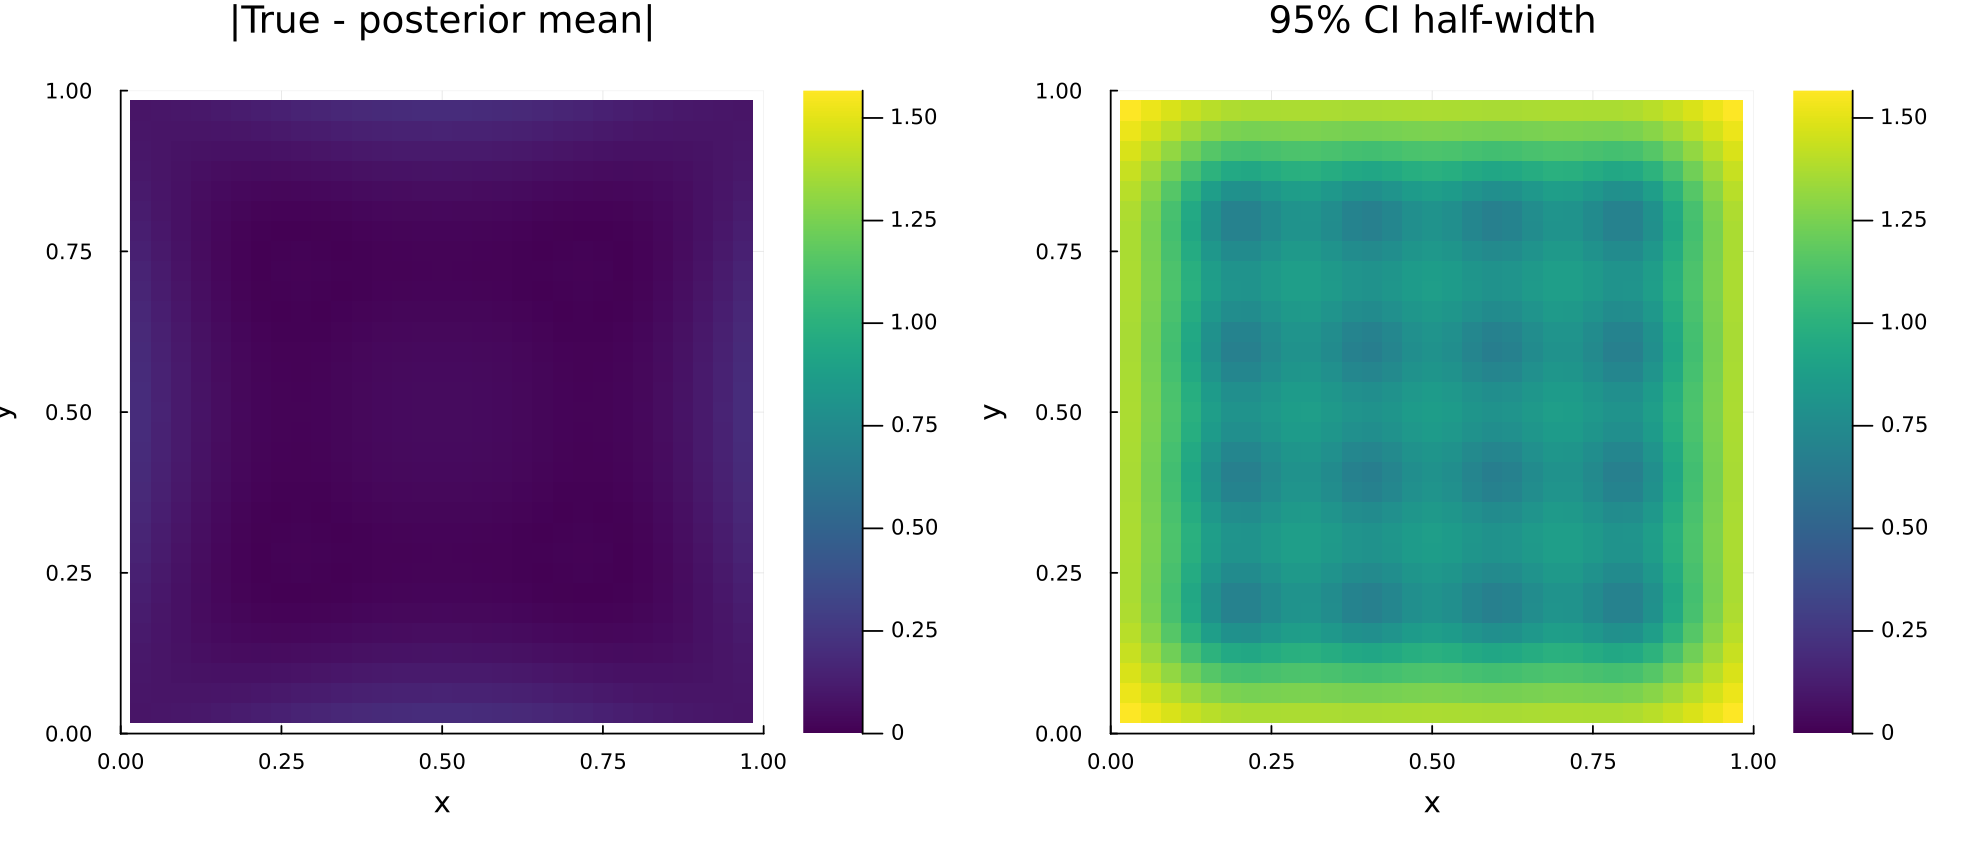

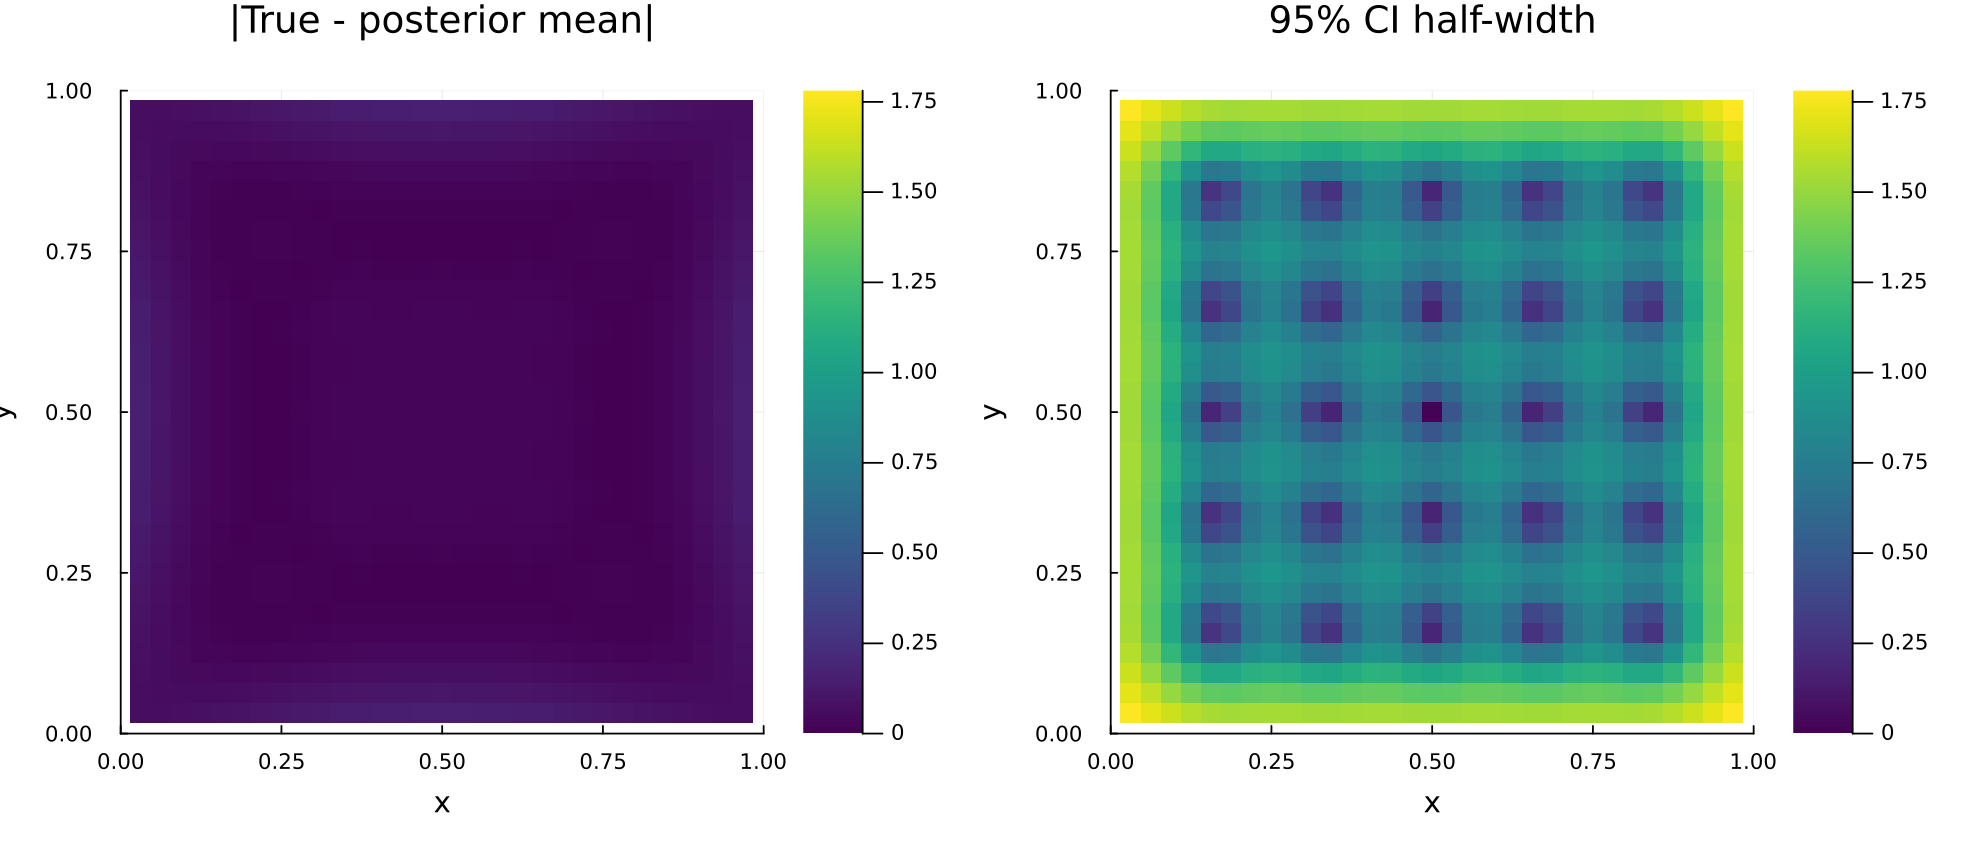

Nx=4 h=0.2 test=31^3 ell=0.2064 C=409.92 RMSE=0.066557 Linf=0.19355 coverage=1.000 CIhalf=1.0139
Nx=5 h=0.16667 test=31^3 ell=0.172 C=327.33 RMSE=0.046333 Linf=0.14934 coverage=1.000 CIhalf=1.1016
Nx=6 h=0.14286 test=31^3 ell=0.14743 C=272.73 RMSE=0.034677 Linf=0.11937 coverage=1.000 CIhalf=0.96988
Nx=8 h=0.11111 test=31^3 ell=0.11467 C=208.73 RMSE=0.021322 Linf=0.081639 coverage=1.000 CIhalf=0.9296


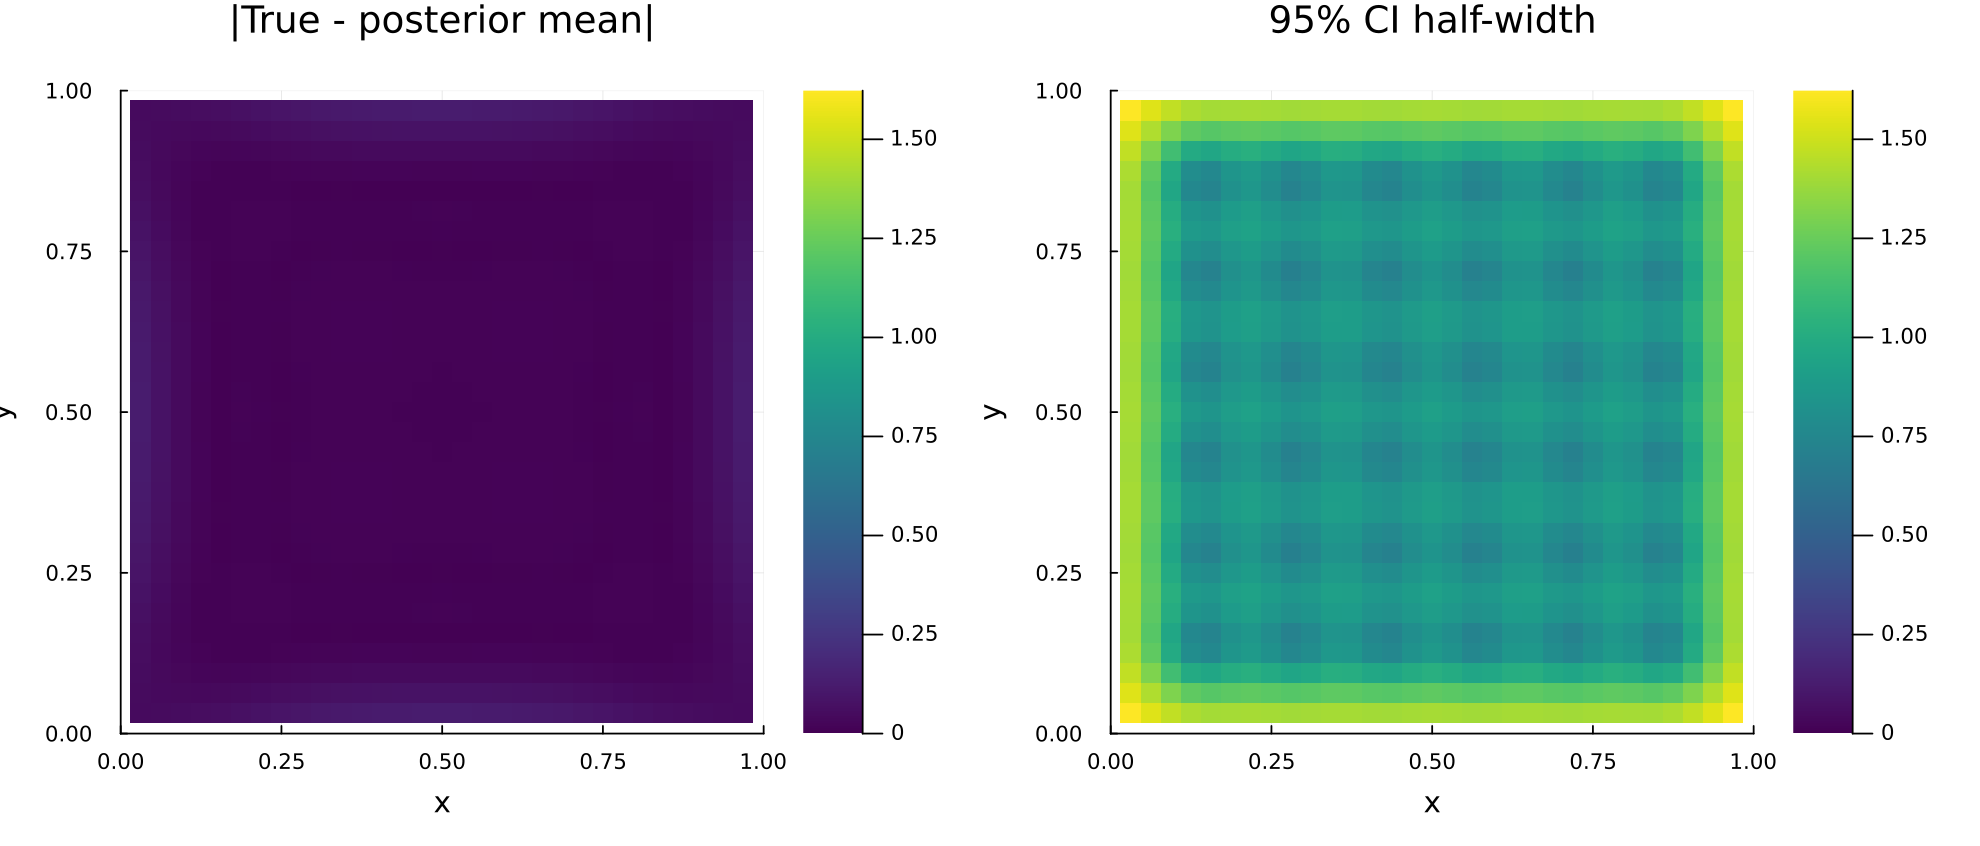

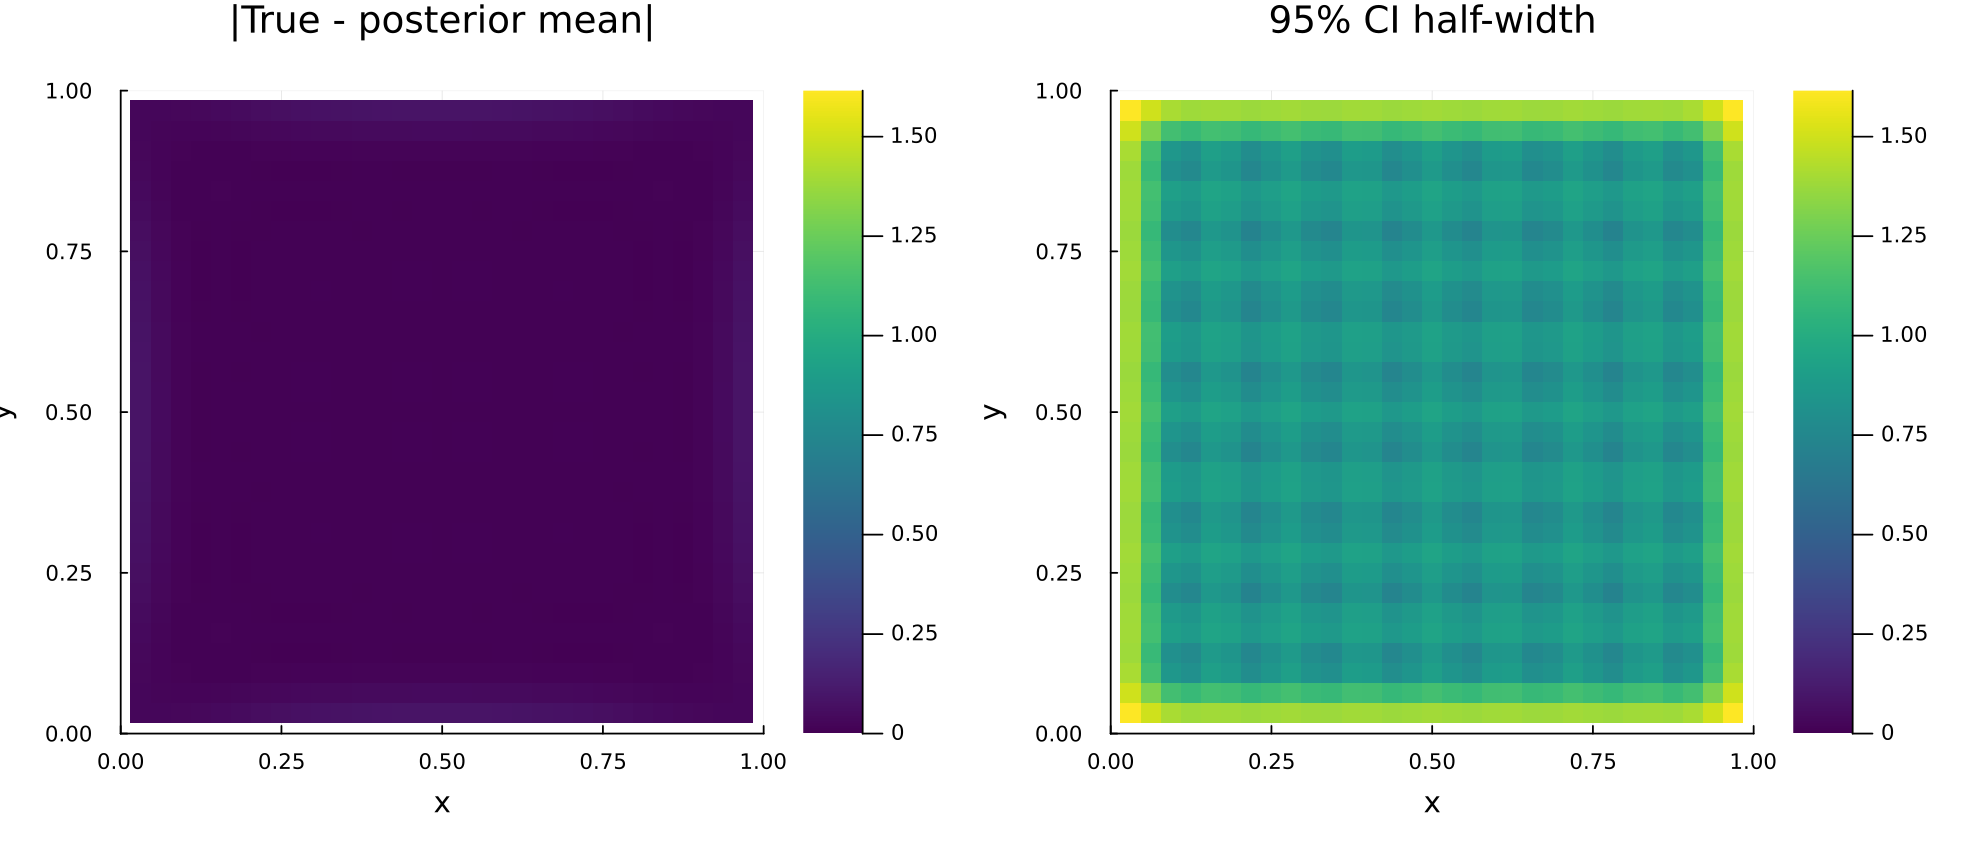

In [9]:
# ============================================================
# Fine-test visualization for rho = 0.5
# |True - posterior mean| versus 95% CI half-width
# SAME color scale
# ============================================================

rho_plot = 0.5
Nx_test_plot = 31

for nx in Nx_list
    h, xs, ys, zs, X, Dh, b, u_fdm = solve_fdm_helmholtz(nx)
    sigma_used = maximum(abs.(u_fdm))
    C_hat, _, _ = estimate_C_coarsening_3d(u_fdm,h,nx; p=p_order)

    out = run_pfdm_helmholtz(nx; rho_adj=rho_plot, C=C_hat,
                             σf=sigma_used, Nx_test=Nx_test_plot)

    U_true = reshape(out.u_true,Nx_test_plot,Nx_test_plot,Nx_test_plot)
    U_post = reshape(out.mu,    Nx_test_plot,Nx_test_plot,Nx_test_plot)
    U_std  = reshape(out.std,   Nx_test_plot,Nx_test_plot,Nx_test_plot)

    zi = argmin(abs.(out.xt .- 0.5))
    zval = out.xt[zi]
    E_post = abs.(U_true[:,:,zi] .- U_post[:,:,zi])
    CI95   = 1.96 .* U_std[:,:,zi]

    common_max = maximum(vcat(vec(E_post),vec(CI95)))
    common_clim = (0.0,common_max)

    p1 = heatmap(out.xt,out.xt,E_post'; title="|True - posterior mean|",
        xlabel="x",ylabel="y",color=:viridis,clim=common_clim,
        aspect_ratio=:equal,xlims=(0,1),ylims=(0,1),
        xticks=0:0.25:1,yticks=0:0.25:1)

    p2 = heatmap(out.xt,out.xt,CI95'; title="95% CI half-width",
        xlabel="x",ylabel="y",color=:viridis,clim=common_clim,
        aspect_ratio=:equal,xlims=(0,1),ylims=(0,1),
        xticks=0:0.25:1,yticks=0:0.25:1)

    fig = plot(p1,p2; layout=(1,2),size=(1100,470),margin=2*Plots.mm,dpi=180)
    display(fig)
    savefig(fig,"helmholtz3d_Nx$(nx)_finetest_rho05.png")

    rmse,linf,cov,hw = posterior_metrics(out.mu,out.std,out.u_true)
    @printf("Nx=%d h=%.5g test=%d^3 ell=%.5g C=%.5g RMSE=%.5g Linf=%.5g coverage=%.3f CIhalf=%.5g\n",
            nx,h,Nx_test_plot,out.ell,C_hat,rmse,linf,cov,hw)
end
